# Appendix A - Measuring Uncertainty

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#A.2.2-Simulation-of-a-Sample" data-toc-modified-id="A.2.2-Simulation-of-a-Sample-1">A.2.2 Simulation of a Sample</a></span></li><li><span><a href="#A.2.3-Many-Imaginary-Samples" data-toc-modified-id="A.2.3-Many-Imaginary-Samples-2">A.2.3 Many Imaginary Samples</a></span></li><li><span><a href="#A.2.4-Law-of-Large-Numbers" data-toc-modified-id="A.2.4-Law-of-Large-Numbers-3">A.2.4 Law of Large Numbers</a></span></li><li><span><a href="#A.2.5-Central-Limit-Theorem" data-toc-modified-id="A.2.5-Central-Limit-Theorem-4">A.2.5 Central Limit Theorem</a></span></li><li><span><a href="#A.2.7-Simulation-of-Approximate-Distributions" data-toc-modified-id="A.2.7-Simulation-of-Approximate-Distributions-5">A.2.7 Simulation of Approximate Distributions</a></span></li><li><span><a href="#A.2.8-Bootstrap" data-toc-modified-id="A.2.8-Bootstrap-6">A.2.8 Bootstrap</a></span></li><li><span><a href="#A.2.9-Hypothesis-Testing" data-toc-modified-id="A.2.9-Hypothesis-Testing-7">A.2.9 Hypothesis Testing</a></span></li><li><span><a href="#A.3.3-Determining-the-Posterior-in-Python" data-toc-modified-id="A.3.3-Determining-the-Posterior-in-Python-8">A.3.3 Determining the Posterior in Python</a></span></li><li><span><a href="#A.4.3-Solving-for-the-Prior-in-Python" data-toc-modified-id="A.4.3-Solving-for-the-Prior-in-Python-9">A.4.3 Solving for the Prior in Python</a></span></li><li><span><a href="#A.4.4-Estimating-the-Posterior-of-the-Mean" data-toc-modified-id="A.4.4-Estimating-the-Posterior-of-the-Mean-10">A.4.4 Estimating the Posterior of the Mean</a></span></li><li><span><a href="#A.5.2-Uniform-Prior" data-toc-modified-id="A.5.2-Uniform-Prior-11">A.5.2 Uniform Prior</a></span></li><li><span><a href="#A.5.3-Estimating-the-Prior" data-toc-modified-id="A.5.3-Estimating-the-Prior-12">A.5.3 Estimating the Prior</a></span></li><li><span><a href="#A.5.4-Paciorek's-Posterior" data-toc-modified-id="A.5.4-Paciorek's-Posterior-13">A.5.4 Paciorek's Posterior</a></span></li></ul></div>

## A.2.2 Simulation of a Sample

In [1]:
# as in the other notebooks, we use numpy
import numpy as np

In [2]:
# remove Python warnings
import warnings
warnings.filterwarnings("ignore")

In [3]:
# setting the seed in Numpy
# the random numbers of Python are not the ones of R,
# so our results are close to the book but not the same
np.random.seed(123456789)

# main parameters of interest
N = 10
mu = -3
sigma = 5

# a sample of size 10 drawn from a normal distribution
# loc is the mean and scale is the standard deviation (sd in R)
x = np.random.normal(loc=mu, scale=sigma, size=N)

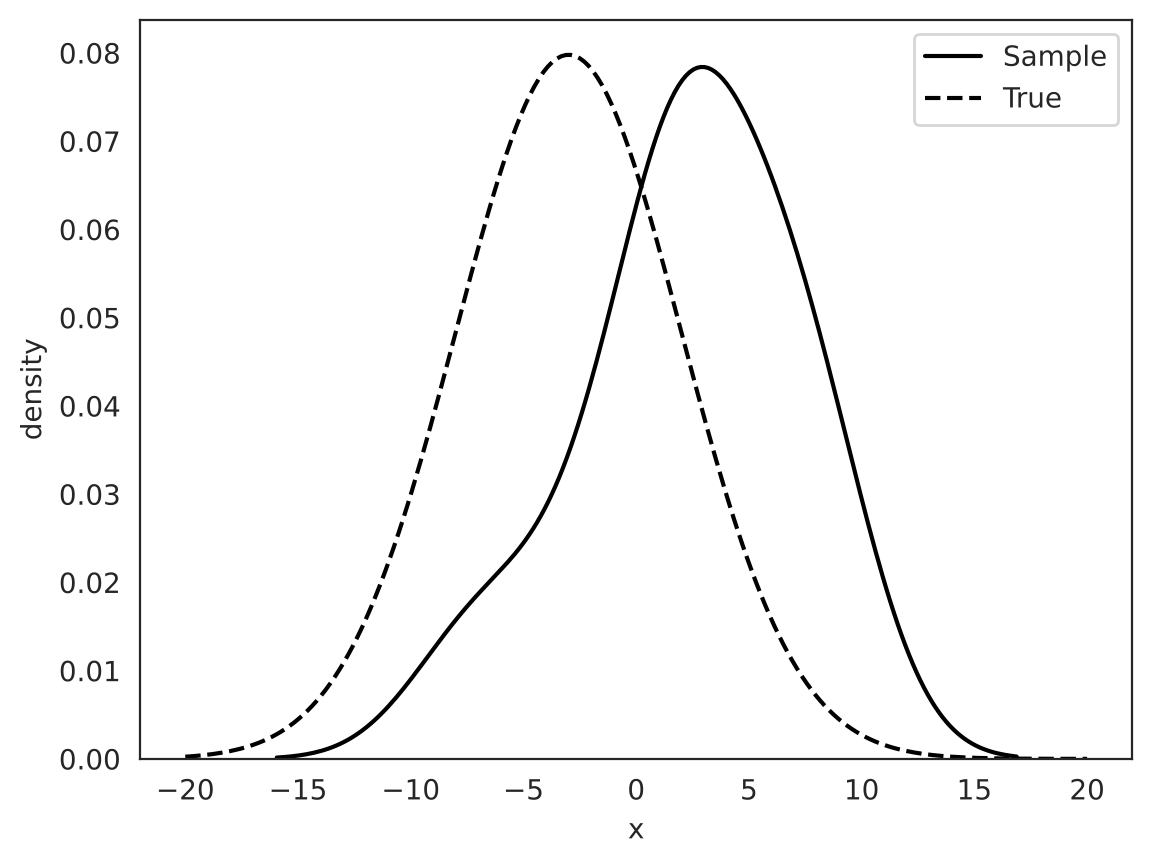

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# plotting with a R-looking plotting style
sns.set_style('white')

# density of the sample
# sns.kdeplot does in one line what density() and plot() do in R
sns.kdeplot(x, color='k', label='Sample')

# true density, computed on 200 values between -20 and 20
# stats.norm.pdf is dnorm in R
grid = np.linspace(-20, 20, 200)
plt.plot(grid, stats.norm.pdf(grid, loc=mu, scale=sigma),
         color='k', linestyle='--', label='True')

plt.xlabel('x')
plt.ylabel('density')
plt.legend()
plt.show()

In [5]:
# in Python mean can be found in the Numpy library
# the true mean is -3, our sample of 10 observations is far from it
print(np.mean(x))

2.31121282443957


In [6]:
# sd in R divides by N-1 and np.std divides by N
# with ddof=1 numpy divides by N-1 too
print(np.std(x, ddof=1))

4.655592226655837


## A.2.3 Many Imaginary Samples

In [7]:
M = 500

# create an empty matrix to fill with the samples
# one row for each sample, one column for each observation
sample_est = np.zeros((M, N))

for m in range(0, M):
    sample_est[m, :] = np.random.normal(loc=-3, scale=5, size=N)

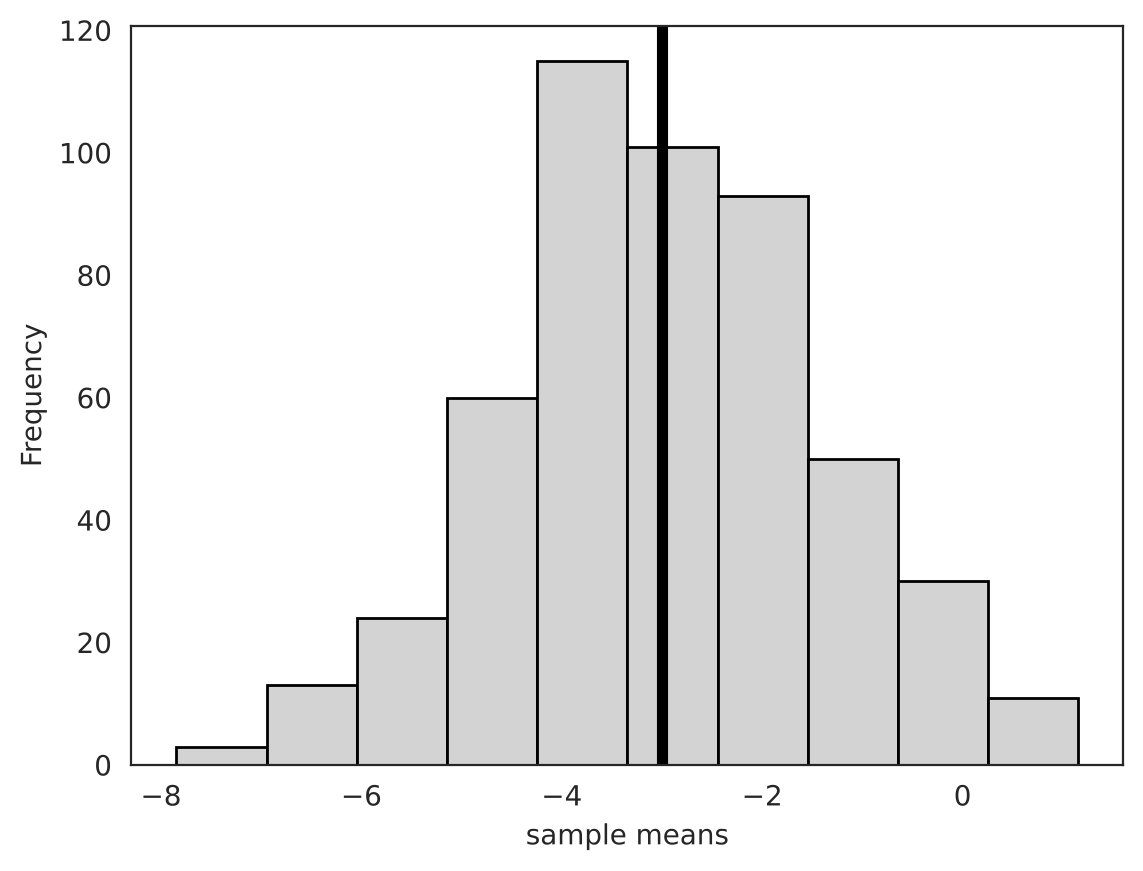

In [8]:
# histogram of the 500 sample means
# axis=1 takes the mean of each row (rowMeans in R)
plt.hist(np.mean(sample_est, axis=1), color='lightgrey', edgecolor='k')

# the true mean
plt.axvline(-3, color='k', linewidth=4)

plt.xlabel('sample means')
plt.ylabel('Frequency')
plt.show()

## A.2.4 Law of Large Numbers

In [9]:
np.random.seed(123456789)
N = 100000
x = np.random.normal(loc=-3, scale=5, size=N)

# with 100,000 observations the sample mean is close to the true value of -3
print(np.mean(x))

-2.9792114458183736


## A.2.5 Central Limit Theorem

In [10]:
M = 1000

# one row for each replication, one column for each sample size
sample_means = np.zeros((M, 4))

for m in range(0, M):
    # python starts counting at 0, so the first column is column 0
    sample_means[m, 0] = np.mean(np.random.normal(loc=-3, scale=5, size=10))
    sample_means[m, 1] = np.mean(np.random.normal(loc=-3, scale=5, size=100))
    sample_means[m, 2] = np.mean(np.random.normal(loc=-3, scale=5, size=1000))
    sample_means[m, 3] = np.mean(np.random.normal(loc=-3, scale=5, size=10000))

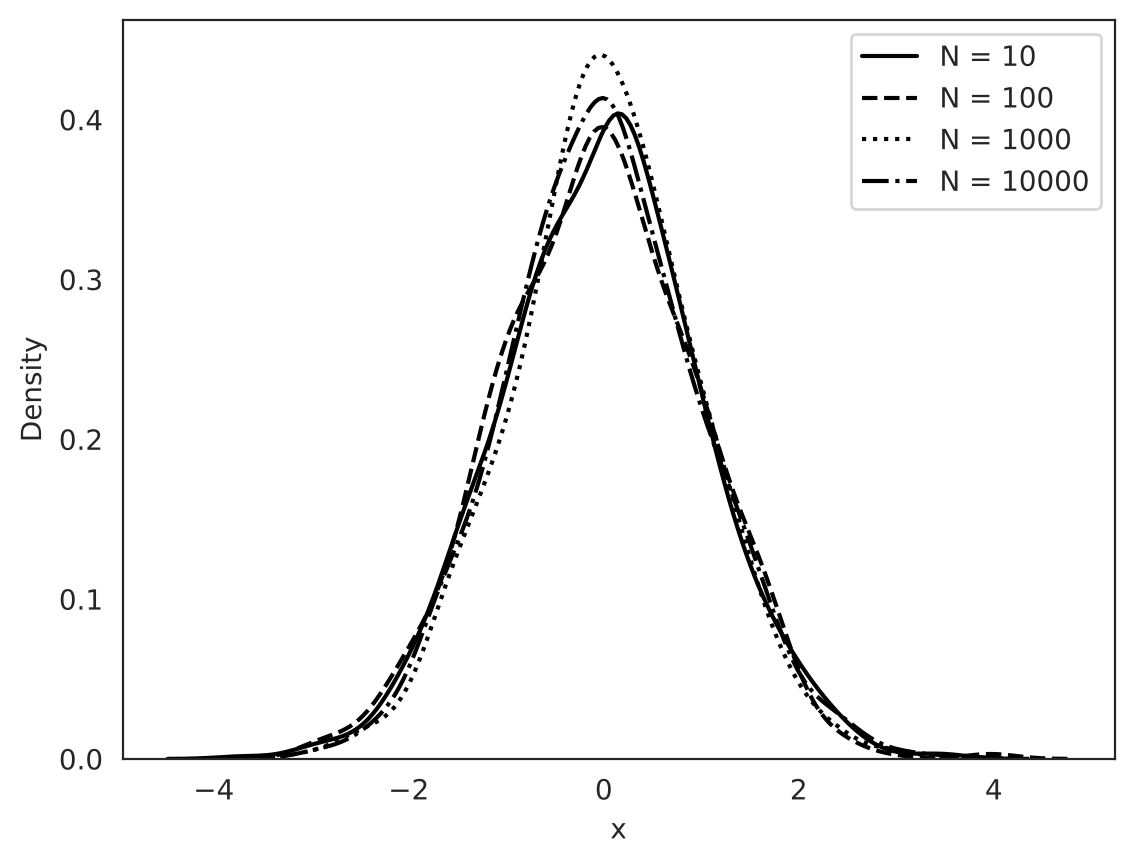

In [11]:
# the sample means are normalized:
# we take out the true mean (-3), divide by the true standard deviation (5)
# and multiply by the square root of the sample size
# the four densities are then close to a standard normal
sizes = [10, 100, 1000, 10000]
styles = ['-', '--', ':', '-.']

for j in range(0, 4):
    z = np.sqrt(sizes[j])*(sample_means[:, j] + 3)/5
    sns.kdeplot(z, color='k', linestyle=styles[j], label='N = ' + str(sizes[j]))

plt.xlabel('x')
plt.ylabel('Density')
plt.legend()
plt.show()

## A.2.7 Simulation of Approximate Distributions

In [12]:
M = 5
N = 10

# first column for the sample mean, second column for its standard error
sample_means = np.zeros((M, 2))

# empty vector to fill with the observations of the five samples
x2 = np.array([])

for m in range(0, M):
    x1 = np.random.normal(loc=mu, scale=sigma, size=N)
    sample_means[m, :] = [np.mean(x1), np.std(x1, ddof=1)/N**0.5]
    # np.append puts x1 at the end of x2, as c(x2,x1) in R
    x2 = np.append(x2, x1)

x2 = np.sort(x2)

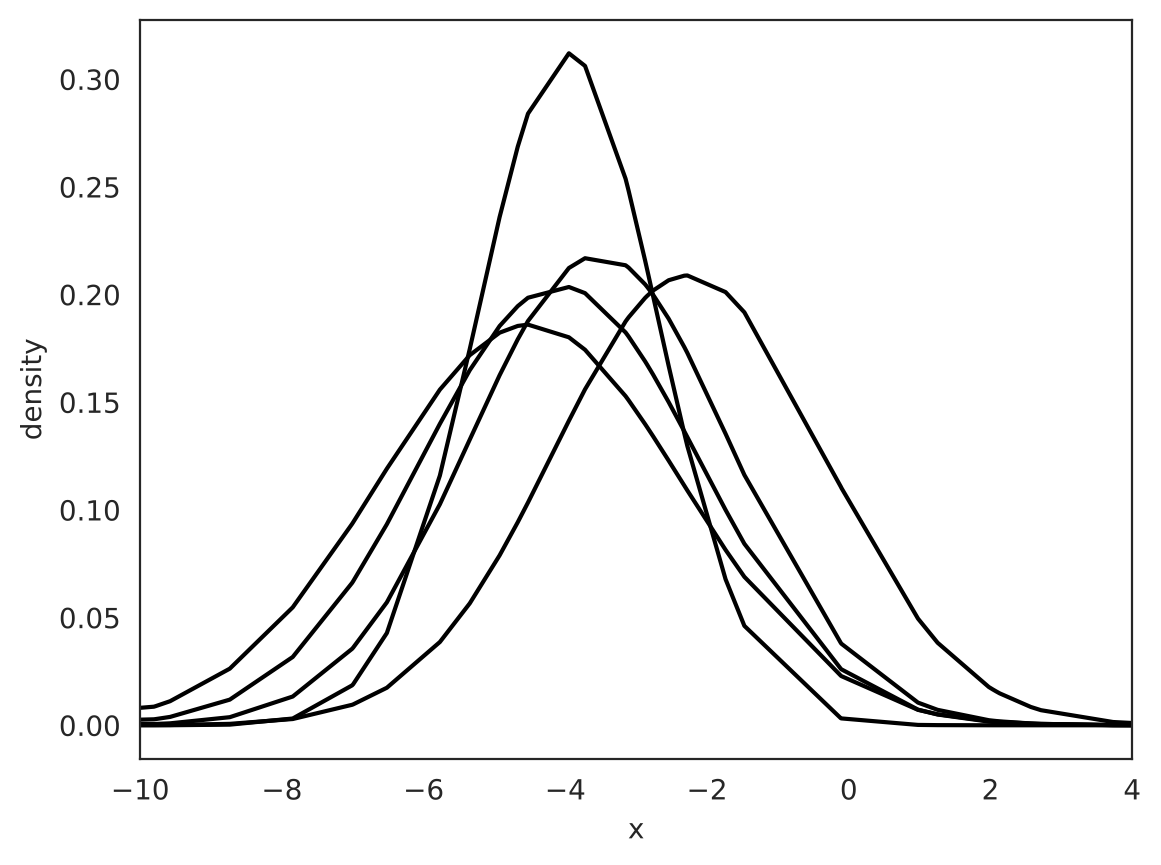

In [13]:
# for each sample, the normal density with the sample mean as mean
# and the standard error as standard deviation
# the densities are computed at the 50 sorted observations of x2
for m in range(0, M):
    plt.plot(x2, stats.norm.pdf(x2, loc=sample_means[m, 0], scale=sample_means[m, 1]),
             color='k')

plt.xlim(-10, 4)
plt.xlabel('x')
plt.ylabel('density')
plt.show()

## A.2.8 Bootstrap

In [14]:
N = 10
x1 = np.random.normal(loc=mu, scale=sigma, size=N)

M = 1000
bs_mean = np.zeros(M)

for m in range(0, M):
    # we draw N positions at random, with replacement
    # python starts counting at 0, so the positions go from 0 to N-1
    index_bs = np.random.randint(0, N, size=N)
    # mean of the pseudo sample
    bs_mean[m] = np.mean(x1[index_bs])

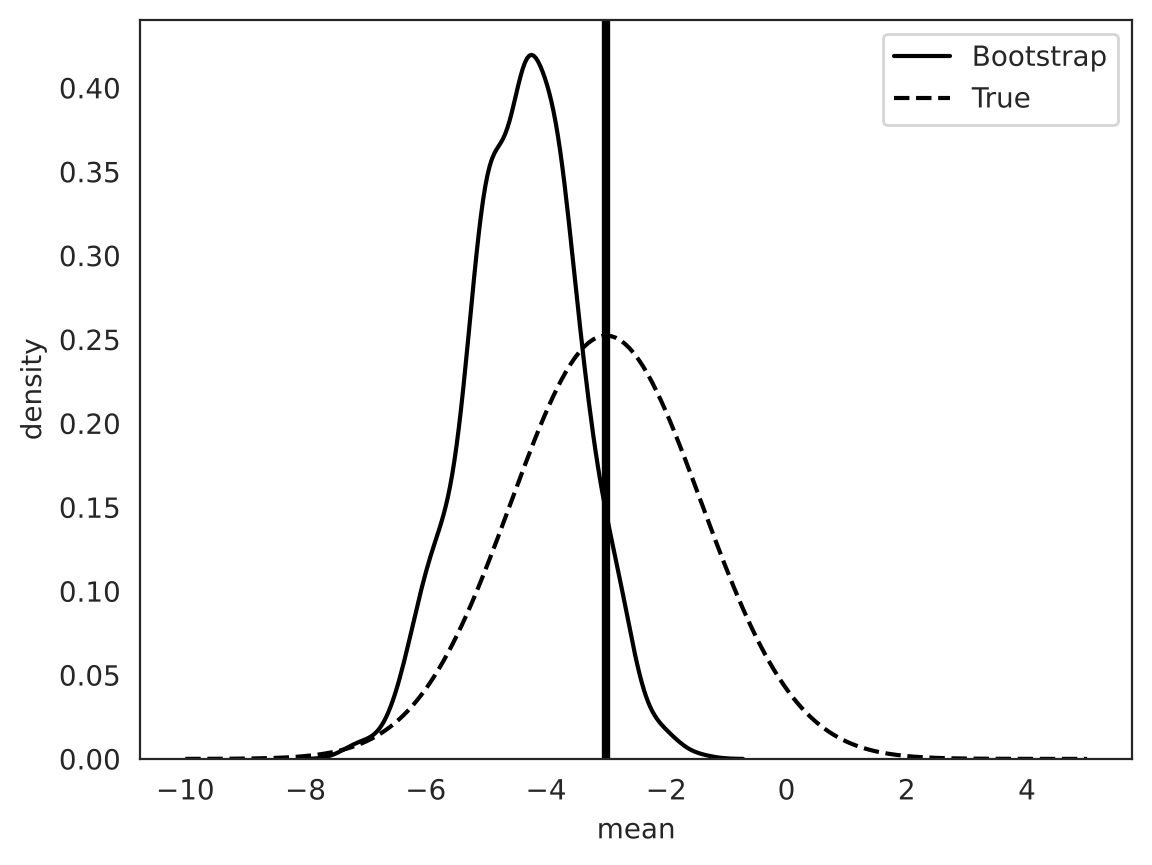

In [15]:
# density of the bootstrapped sample means
sns.kdeplot(bs_mean, color='k', label='Bootstrap')

# true distribution of the sample mean:
# normal with mean mu and standard deviation sigma/sqrt(N)
grid = np.linspace(-10, 5, 200)
plt.plot(grid, stats.norm.pdf(grid, loc=mu, scale=sigma/np.sqrt(N)),
         color='k', linestyle='--', label='True')

# the true mean
plt.axvline(mu, color='k', linewidth=3)

plt.xlabel('mean')
plt.ylabel('density')
plt.legend()
plt.show()

## A.2.9 Hypothesis Testing

We keep the sample mean of the book (-3.49) in this section, because the mean of our own sample of 10 is 2.31 and the hypothesis would not be rejected with it.

In [16]:
alpha = 0.05

# critical value
# stats.norm.ppf is qnorm in R
# x is the large sample of section A.2.4 at this point (in the R code of the book too),
# so the standard deviation is 4.99 and not the 5.10 of the text
critical_value = np.std(x, ddof=1)*stats.norm.ppf(alpha)/np.sqrt(10)
print(critical_value)

-2.5972562200306992


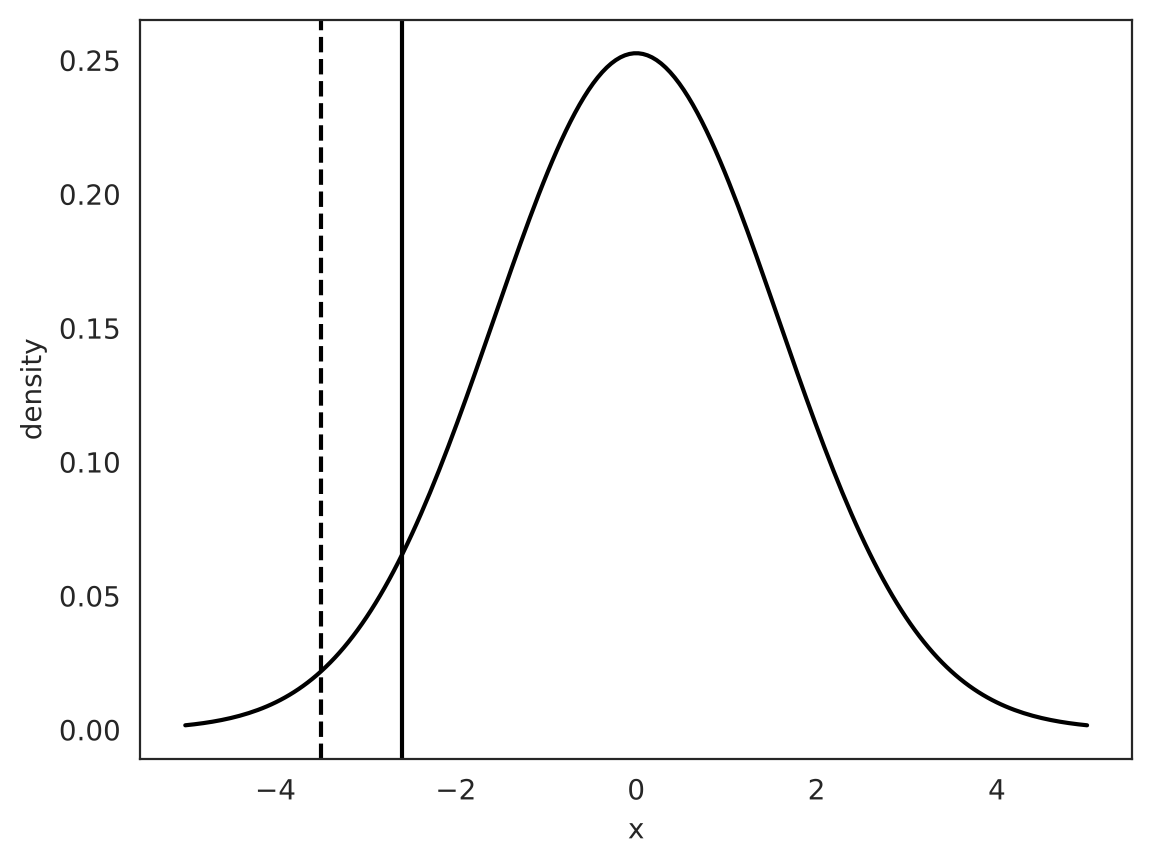

In [17]:
# density of the sample mean when the true mean is 0
grid = np.linspace(-5, 5, 200)
plt.plot(grid, stats.norm.pdf(grid, loc=0, scale=np.std(x, ddof=1)/np.sqrt(10)),
         color='k')

# the critical value (solid line)
plt.axvline(critical_value, color='k')

# the sample mean of the book (dashed line)
plt.axvline(-3.49, color='k', linestyle='--')

plt.xlabel('x')
plt.ylabel('density')
plt.show()

In [18]:
# p-value: probability of a sample mean below -3.49 when the true mean is 0
# stats.norm.cdf is pnorm in R
print(stats.norm.cdf(np.sqrt(10)*((-3.49)/np.std(x, ddof=1))))

0.013544527940378378


## A.3.3 Determining the Posterior in Python

In [19]:
def log_norm(x, mu, sigma):
    """
    Log likelihood of the sample x
    when the true distribution is normal with mean mu and standard deviation sigma
    """
    z = (x - mu)/sigma
    return np.sum(np.log(stats.norm.pdf(z)) - np.log(sigma))

# the 100 possible values of the true mean, from -9.85 to 5
# (the text of the book says between -5 and 10, the R code gives this)
# np.arange(1, 101) is c(1:100) in R, python leaves out the last number
Theta = 15*np.arange(1, 101)/100 - 10

# uniform approximation
# np.repeat is rep in R
g = np.repeat(1/100, 100)

# log likelihood of the sample x1 for each possible true mean
# sapply in R applies the function to each value of Theta, a for loop does it here
h = np.zeros(100)
for k in range(0, 100):
    h[k] = log_norm(x1, Theta[k], 5)

# Bayes' rule: likelihood times prior, divided by the sum over all the possible true means
gamma = np.exp(h + np.log(g))/np.sum(np.exp(h + np.log(g)))

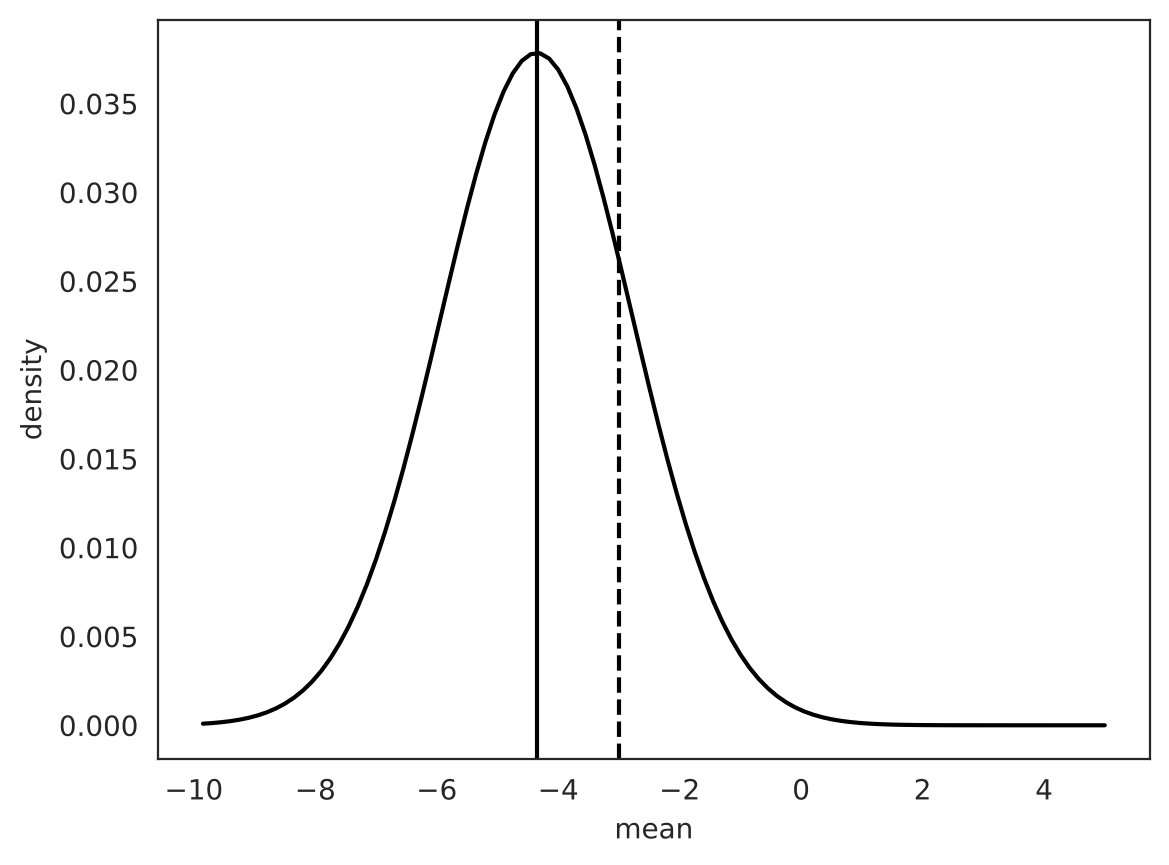

In [20]:
# posterior distribution of the mean
plt.plot(Theta, gamma, color='k')

# the analog estimate, which is the mean of the sample (solid line)
plt.axvline(np.mean(x1), color='k')

# the true value (dashed line)
plt.axvline(-3, color='k', linestyle='--')

plt.xlabel('mean')
plt.ylabel('density')
plt.show()

## A.4.3 Solving for the Prior in Python

In [21]:
# 300 possible true means, evenly spaced between the smallest
# and the largest observation of the 500 samples
Theta = (np.max(sample_est) - np.min(sample_est))*np.arange(1, 301)/300 + np.min(sample_est)

# log likelihood of each sample (500 rows) for each possible true mean (300 columns)
# it takes a few seconds
H = np.zeros((500, 300))
for i in range(0, 500):
    x = sample_est[i, :]
    for k in range(0, 300):
        H[i, k] = log_norm(x, Theta[k], 5)

In [22]:
# we start with a uniform prior
g0 = np.repeat(1/300, 300)

# np.tile repeats the vector g0 on 500 rows, to get a matrix of the same size as H
log_G0 = np.log(np.tile(g0, (500, 1)))

# the book has sum(exp(H) + log_G0) for the sum below
# the bracket is not at the right place, but g1 is the same because the sum cancels out in g1
gamma0 = np.exp(H + log_G0)/np.sum(np.exp(H + log_G0))

# new estimate of prior
# axis=0 takes the sum of each column (colSums in R)
g1 = np.sum(gamma0, axis=0)/np.sum(gamma0)

In [23]:
# second iteration, with g1 as prior
log_G1 = np.log(np.tile(g1, (500, 1)))
gamma1 = np.exp(H + log_G1)/np.sum(np.exp(H + log_G1))
g2 = np.sum(gamma1, axis=0)/np.sum(gamma1)

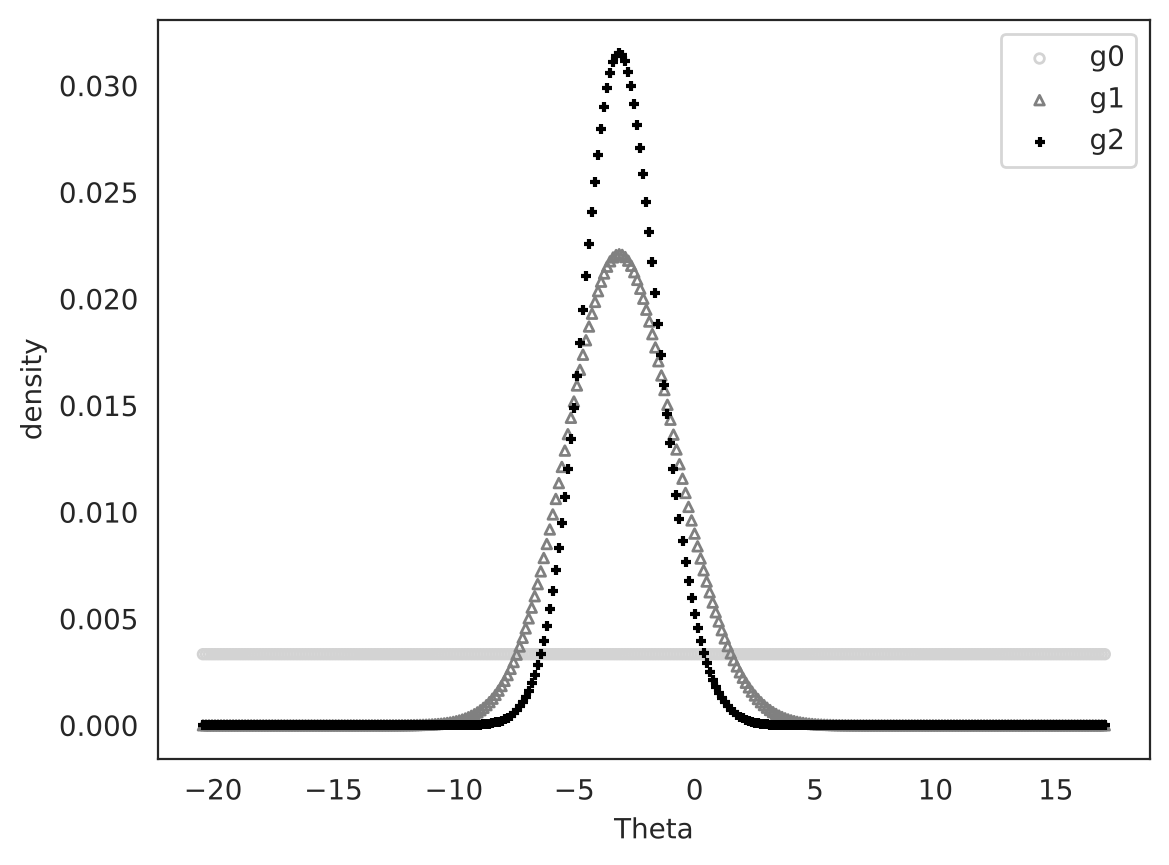

In [24]:
# the uniform prior and the first two iterations
# s is the size of the markers
plt.scatter(Theta, g0, s=12, facecolors='none', color='lightgrey', label='g0')
plt.scatter(Theta, g1, s=12, marker='^', facecolors='none', color='grey', label='g1')
plt.scatter(Theta, g2, s=12, marker='+', color='k', label='g2')

plt.xlabel('Theta')
plt.ylabel('density')
plt.legend()
plt.show()

In the loop we divide each row of gamma by its own sum (rowSums() in R), as the errata of the book says for this section, and not by the sum of the whole matrix as in the R code of the book.

In [25]:
eps = 1e-3 # small number
g_old = g1
g_new = g2
diff = np.sum(np.abs(g_new - g_old))

while diff > eps:
    g_old = g_new
    # the prior becomes 0 for the true means far from the data
    # log(0) is -inf in numpy as in R, and exp(-inf) gives 0 again
    log_G = np.log(np.tile(g_old, (500, 1)))
    gamma = np.exp(H + log_G)
    # axis=1 takes the sum of each row (rowSums in R)
    # reshape(500, 1) puts the 500 sums in a column,
    # so that numpy divides each row by its own sum
    gamma = gamma/np.sum(gamma, axis=1).reshape(500, 1)
    g_new = np.sum(gamma, axis=0)/np.sum(gamma)
    diff = np.sum(np.abs(g_new - g_old))
    #print(diff)

In [26]:
J = 100000

# a long vector where each possible true mean is repeated
# in proportion of its weight in the prior
# np.repeat takes the values and the number of times to repeat each of them
# astype(int) because this number has to be a whole number
g_dist = np.repeat(Theta, np.round(J*g_new).astype(int))

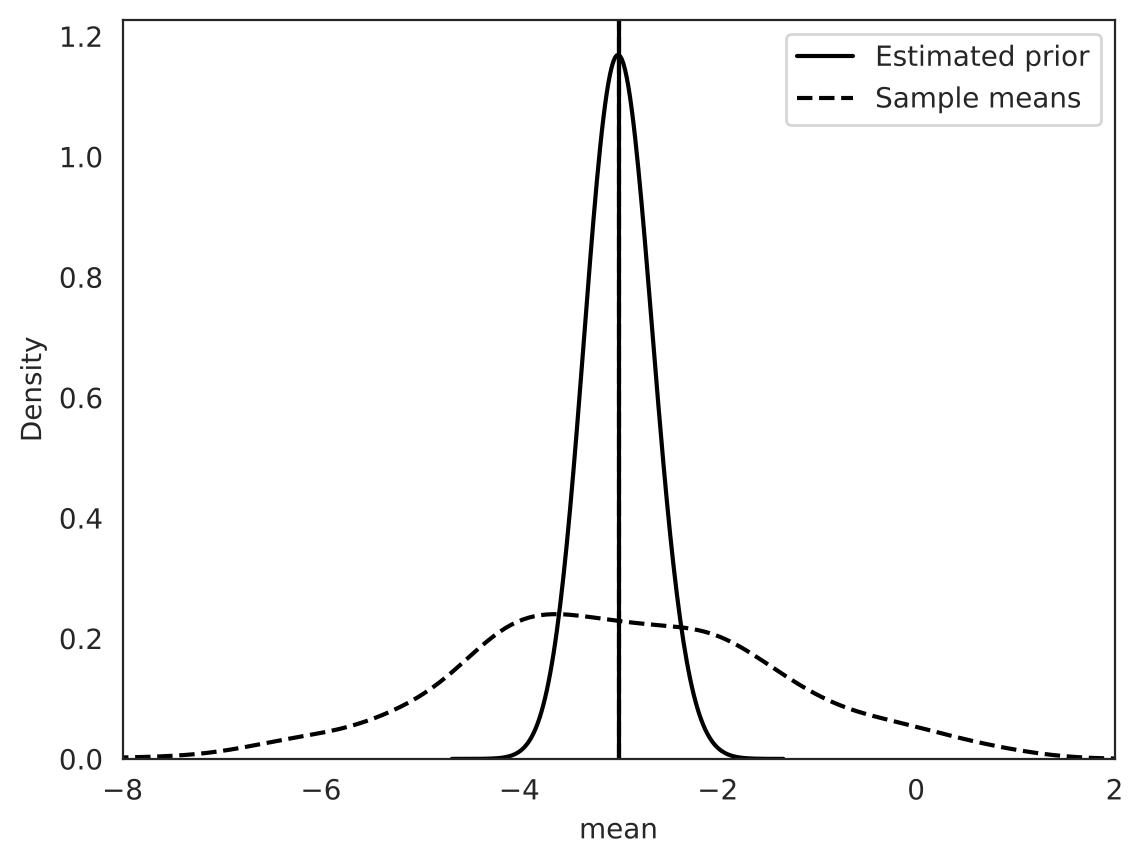

In [27]:
# density of the estimated prior (solid line)
# the values of Theta are far apart compared to the width of the prior,
# so we ask for more smoothing with bw_adjust (the curve is a row of spikes if not)
sns.kdeplot(g_dist, bw_adjust=3, color='k', label='Estimated prior')

# density of the observed sample means (dashed line)
sns.kdeplot(np.mean(sample_est, axis=1), color='k', linestyle='--', label='Sample means')

# mean of the estimated prior (solid line) and true mean (dashed line)
plt.axvline(np.sum(g_new*Theta), color='k')
plt.axvline(-3, color='k', linestyle='--')

plt.xlim(-8, 2)
plt.xlabel('mean')
plt.ylabel('Density')
plt.legend()
plt.show()

## A.4.4 Estimating the Posterior of the Mean

In [28]:
# log likelihood of the sample x1 for each of the 300 possible true means
h_x1 = np.zeros(300)
for k in range(0, 300):
    h_x1[k] = log_norm(x1, Theta[k], 5)

# Bayes' rule with the estimated prior
gamma_x1 = np.exp(h_x1 + np.log(g_new))/np.sum(np.exp(h_x1 + np.log(g_new)))

In [29]:
J = 100000
g_dist_x1 = np.repeat(Theta, np.round(J*gamma_x1).astype(int))

In [30]:
# mean of the sample x1 (the analog estimate)
print(np.mean(x1))

# mean of the posterior
print(np.sum(gamma_x1*Theta))

-4.355290290833565
-3.049366319011077


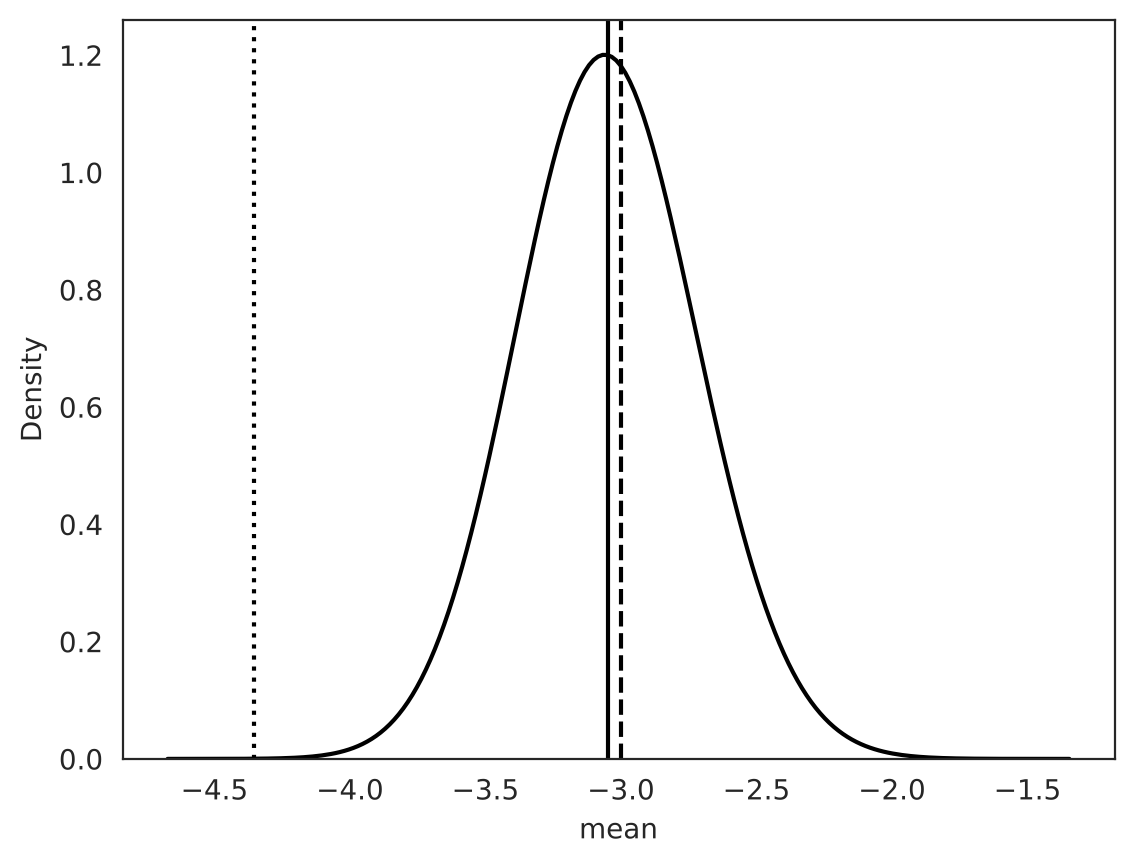

In [31]:
# density of the estimated posterior
# with more smoothing, as for the prior
sns.kdeplot(g_dist_x1, bw_adjust=3, color='k')

# true mean (dashed line), mean of the sample (dotted line)
# and mean of the posterior (solid line)
plt.axvline(-3, color='k', linestyle='--')
plt.axvline(np.mean(x1), color='k', linestyle=':')
plt.axvline(np.sum(gamma_x1*Theta), color='k')

plt.xlabel('mean')
plt.ylabel('Density')
plt.show()

## A.5.2 Uniform Prior

In [32]:
def lchoose(N, K):
    """
    Log of the binomial coefficient (lchoose in R)
    * the binomial coefficient is N!/(K!(N-K)!)
    * which is (N-K+1)*...*N divided by 1*...*K
    * we take the sum of the logs, the products are too big with many at bats
    """
    return np.sum(np.log(np.arange(N-K+1, N+1))) - np.sum(np.log(np.arange(1, K+1)))

def log_bin(N, p_hat, p):
    """
    Log of the binomial likelihood
    * N is the number of at bats and p_hat the batting average
    * p is the true probability of a hit
    """
    # number of hits
    K = int(np.round(p_hat*N))
    return lchoose(N, K) + K*np.log(p) + (N-K)*np.log(1-p)

# the possible true probabilities, from 0.001 to 0.999
Theta = np.arange(1, 1000)/1000
log_g = np.log(np.repeat(1/1000, 999))

# Paciorek: 3 at bats and a batting average of 1
# numpy computes log_bin for all the values of Theta at once, no need for sapply
h_jp = log_bin(3, 1, Theta)
gamma_jp = np.exp(h_jp + log_g)/np.sum(np.exp(h_jp + log_g))

J = 100000
# the book repeats j (from 1 to 999) and not Theta[j] here,
# so in the plot the batting average is multiplied by 1000 (341 for Ruth)
gamma_dist_jp = np.repeat(np.arange(1, 1000), np.round(J*gamma_jp).astype(int))

# mean
print(np.sum(gamma_jp*Theta))

0.7995997331998663


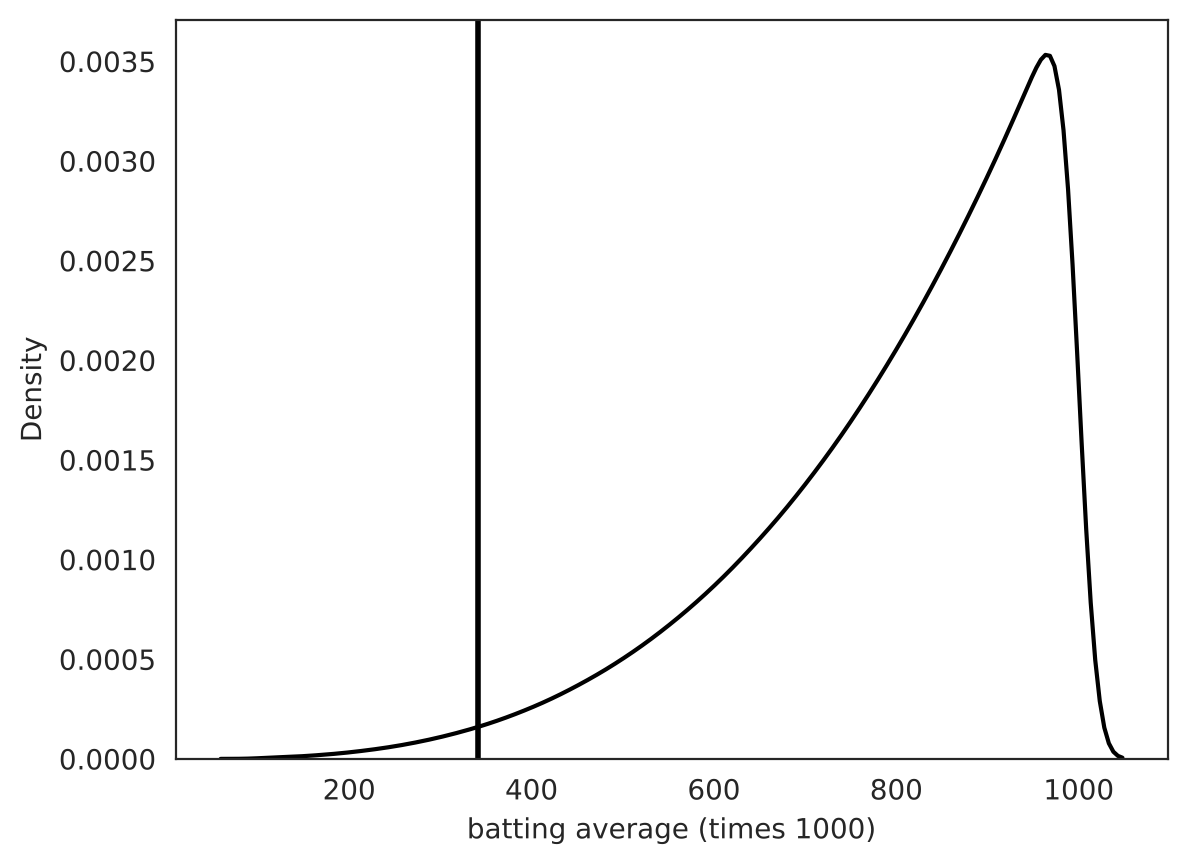

In [33]:
# density of the posterior of Paciorek with a uniform prior
sns.kdeplot(gamma_dist_jp, color='k')

# lifetime batting average of Babe Ruth
plt.axvline(341, color='k', linewidth=2)

plt.xlabel('batting average (times 1000)')
plt.ylabel('Density')
plt.show()

In [34]:
# probability that the true batting average of Paciorek is above the one of Ruth
# python starts counting at 0, so Theta = 0.342 is at position 341 (342 in R)
print(np.sum(gamma_jp[341:999]))

0.9863720668776885


## A.5.3 Estimating the Prior

In [35]:
import pandas as pd

M = 1000
# data set created from Lahman's data.
# limited the observations for computational reasons.
x = pd.read_csv('../data/bat_ave.csv', nrows=M)
x.head()

,playerID,AB,H,AVE
0,aardsda01,4,0,0.000000
1,aaronha01,12364,3771,0.304998
2,aaronto01,944,216,0.228814
3,aasedo01,5,0,0.000000
4,abadan01,21,2,0.095238


In [36]:
# log likelihood of each player (rows) for each possible true probability (columns)
H = np.zeros((M, 999))
for m in range(0, M):
    # AB is already a whole number in our dataframe, so no round() here
    H[m, :] = log_bin(x['AB'][m], x['AVE'][m], Theta)

# first iteration, from the uniform prior
log_G = np.tile(log_g, (M, 1))
gamma0 = np.exp(H + log_G)/np.sum(np.exp(H + log_G))
g1 = np.sum(gamma0, axis=0)/np.sum(gamma0)

This uses the same method for estimating the prior as above.

In [37]:
eps = 0.001
g_old = np.exp(log_g)
g_new = g1
diff = np.sum(np.abs(g_new - g_old))

while diff > eps:
    g_old = g_new
    Log_G = np.log(np.tile(g_old, (M, 1)))
    Gamma = np.exp(H + Log_G)
    # each row is divided by its own sum (rowSums in R)
    Gamma = Gamma/np.sum(Gamma, axis=1).reshape(M, 1)
    g_new = np.sum(Gamma, axis=0)/np.sum(Gamma)
    diff = np.sum(np.abs(g_new - g_old))
    #print(diff)

## A.5.4 Paciorek's Posterior

In [38]:
# Bayes' rule with the likelihood of Paciorek and the estimated prior
gamma_jp2 = np.exp(h_jp + np.log(g_new))/np.sum(np.exp(h_jp + np.log(g_new)))

J = 100000
# vectors for graphing, made with np.repeat as above
g_dist_mlb = np.repeat(Theta, np.round(J*g_new).astype(int))
gamma_dist_jp2 = np.repeat(Theta, np.round(J*gamma_jp2).astype(int))

# mean
print(np.sum(gamma_jp2*Theta))

0.25068790349461345


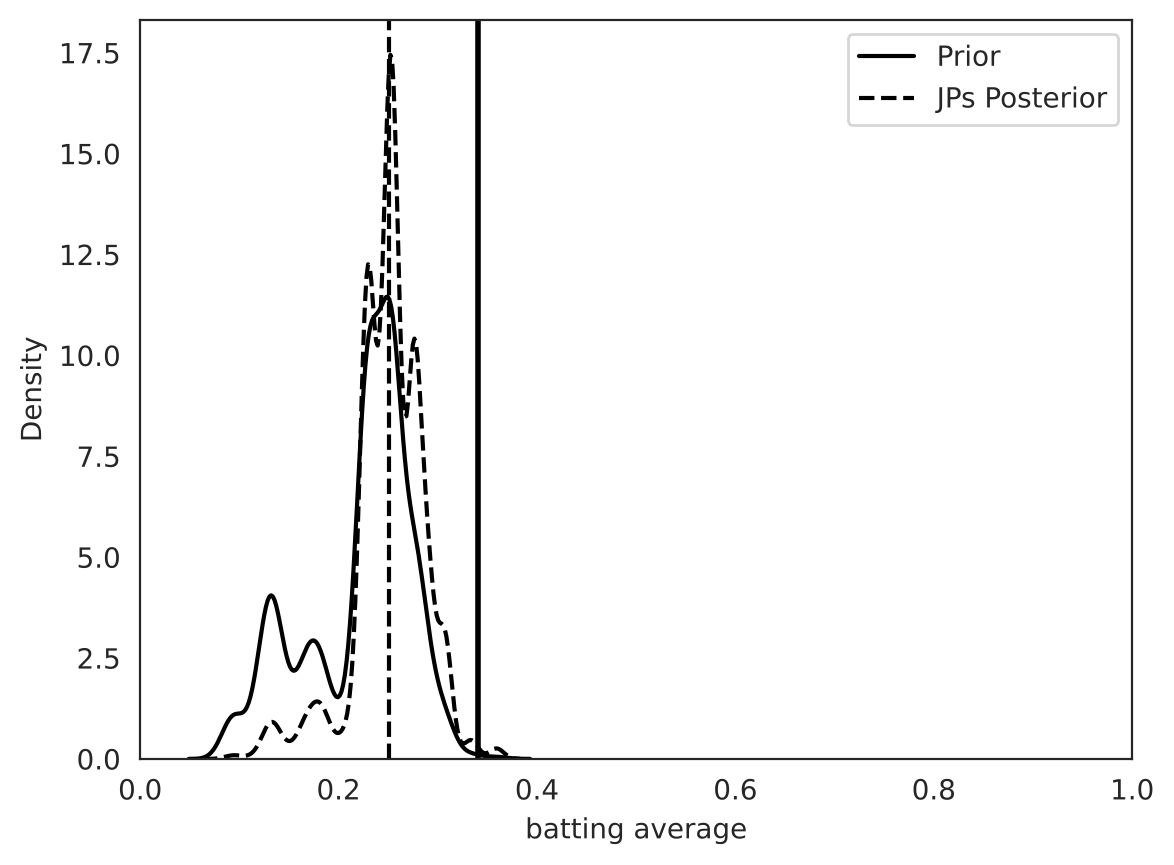

In [39]:
# density of the estimated prior (solid line)
# bw_adjust=2 smooths the curves a bit more, to get the look of the figure of the book
sns.kdeplot(g_dist_mlb, bw_adjust=2, color='k', label='Prior')

# density of the posterior of Paciorek (dashed line)
sns.kdeplot(gamma_dist_jp2, bw_adjust=2, color='k', linestyle='--', label='JPs Posterior')

# mean of the posterior (dashed line) and batting average of Ruth (solid line)
plt.axvline(np.sum(gamma_jp2*Theta), color='k', linestyle='--')
plt.axvline(0.341, color='k', linewidth=2)

plt.xlim(0, 1)
plt.xlabel('batting average')
plt.ylabel('Density')
plt.legend()
plt.show()

In [40]:
# probability that the true batting average of Paciorek is above the one of Ruth
print(np.sum(gamma_jp2[341:999]))

0.004715467825630661
